# Team members:
  * ### Abdallah Said,
  * ### Miłosz Stec,
  * ### Maciek Kołakowski.

# <font color="red"> **1. Task Definition** </font>

*What is the engineering problem, and what constitutes a successful
solution? Define the objective, inputs and outputs, relevant constraints and
assumptions, and the criteria used to evaluate the solution*

---

## Theme:
Evolutionary Optimization in Engineering Design - application of evolutionary
algorithms to complex, multi-objective engineering problems with simulation-based or
experimental evaluation.

---

## Topic:
### <font color="green"> **Multi-objective PID tuning for a drone** </font>

---

## Goal:
The goal is to propose, implement and tune a genetic algorithm (GA) that finds the PID gains of the drone's altitude controller.

---

### Data:
All data comes from the Webots simulation (DJI Mavic 2 Pro). Every candidate PID is flown in one simulated episode and the controller returns its performance metrics.

---

### Main experiment and comparison:
The GA searches for the PID gains that minimise the cost Q in one fixed flight scenario (take-off, hover, forward flight, landing).

---

## Order of work:
1. Configure the enviroment
2. Process the dataset (necessary exploration, cleaning, preprocessing, splitting)
3. Analyze the dataset
4. importing the dataset into enviroment
5. build a represantaion for the data suitable for the algorithm!
6. objective function
7. cofiguration of an algorithm
8. fine-tune the model
9. Validate the model
10. Test the model
11. prepare report

---

## Team work plan:

### 1 lab:
1. Configure the enviroment  (Abdallah)
2. Process the dataset (necessary exploration, cleaning, preprocessing, splitting) (Maciek)
3. Analyze the dataset (Miłosz)
4. importing the dataset into enviroment (Abdallah)

### 2 lab:  
5. Build a represantaion for the data suitable for the algorithm (Miłosz)
6. Objective function (Abdallah)
7. Cofiguration of an algorithm (Maciek)

### 3 lab:  
8. Fine-tune the model (Maciek)
9. Validate the model (Abdallah)
10. Test the model (Miłosz)
11. Prepare report  (All)

---

# <font color="red"> **2. Data / system representation and preparation** </font>

*Where does the data come from:
measurements, simulations, synthetic generation, or a combination of these? Examine its relevant properties and potential quality issues, such as noise, missing values, outliers, imbalance, or limited coverage. Describe the required preprocessing and, where applicable, the division into training, validation, and test sets.*

---

The data is generated by simulation, not taken from a file. The GA writes the candidates to a CSV file, Webots flies each of them with the C controller (`webots_pid/controllers/drone_pid`) and writes the metrics back. No training/validation/test split is needed: every candidate is evaluated directly in the simulator.

**Flight scenario (identical for every candidate, full world reset before each episode):**

| Time | Altitude target | Action |
|---|---|---|
| 0 – 2.5 s | ramp 0.6 m/s up to 1.5 m | take-off |
| 2.5 – 3 s | 1.5 m | hover |
| 3 – 6 s | 1.5 m | forward flight at 0.35 m/s |
| from 6 s | 0.1 m | landing (episode ends 0.5 s after touchdown, max 12 s) |

Start position (0, 0, 0.1), no wind, no payload, simulation step 8 ms. The drone counts as flipped when roll or pitch exceeds 1.2 rad.

**Quality issues found and fixed in the simulation:**
* motor mixing error (rear-right motor had the wrong sign of the pitch term),
* the horizontal velocity loop used world-frame velocity instead of body-frame velocity, so the drone drifted away,
* metrics were wrong when the drone did not reach the target altitude (rise/settling time = 0 looked like the best result).

At first we used a ready dataset (Kaggle and our own CSV), but it limited the PID ranges to the values that happened to be in the file, so we removed it.

---

# <font color="red"> **3. Input representation / features** </font>

*What information is provided to the model or solution method, and why? Describe any feature extraction, engineering, or selection required. Consider whether the selected representation omits relevant information or introduces unnecessary redundancy.*

---

## Decision variables (searched by the GA)

| Variable | Lower bound | Upper bound |
|---|---|---|
| `P_gain` | 0.7 | 8 |
| `I_gain` | 0.001 | 2 |
| `D_gain` | 0.5 | 4 |

Why these bounds: the vertical controller output is limited to ±5, so the upper bounds let each PID term reach that limit (P = 8 saturates at 0.6 m error, the integral is limited to ±2.5 so I = 2 gives up to 5, vertical speed is about 1 m/s so D = 4 gives up to 4). The lower bounds keep every term active.

Each gain is stored as a gene in [0, 1]:

    value = lower + gene * (upper - lower)

so crossover and mutation work the same way for all three gains.

## Fixed flight conditions

Initial roll, pitch and yaw = 0, wind speed = 0, payload = 0.

## Observed performance (from the simulation)

Altitude metrics are measured only while the target is 1.5 m (t < 6 s).

| Metric | Meaning | Unit |
|---|---|---|
| `rise_time` | first time the drone reaches 90% of 1.5 m (12 s if never) | s |
| `settling_time` | time after which the altitude stays within ±5 cm of 1.5 m (12 s if never) | s |
| `overshoot_percent` | highest altitude above 1.5 m | % |
| `steady_state_error` | mean altitude error in the last second before landing | m |
| `total_energy_consumed` | sum of motor speeds over time | rad/s · s |
| `stability_score` | 1 / (1 + mean squared altitude error) | 0 – 1 |
| `flipped` | drone flipped over | 0 / 1 |

## Cost function (minimised)

Each metric is divided by a reference value (rise 7 s, settling 6 s, overshoot 25 %, error 1.5 m, energy 3500):

    Q = 0.4 * rise_time + 0.6 * settling_time + 1.0 * overshoot_percent
      + 0.1 * steady_state_error + 0.1 * total_energy_consumed
      + 0.8 * (1 / stability_score - 1)

A drone that never reaches 90% of 1.5 m gets an extra +2 (without it such a drone had a lower Q than drones that reached the altitude with some overshoot). A flipped drone gets Q = 1000.

---

# <font color="red"> **4. Model(s) / solution method** </font>

*Which model, algorithm, or solution method is used, and why is it suitable for the problem? Describe its structure, key parameters, and the training, fitting, identification, or optimization procedure. Where applicable, define a simple baseline or reference approach for comparison.*

Genetic algorithm. It fits this problem because Q comes from a simulation: there is no formula to differentiate, only a value for each tested PID.

Steps:
1. **Initial population:** random, spread evenly over the bounds (Latin Hypercube Sampling: every gene range is split into equal parts and each part gets exactly one individual).
2. **Evaluation:** every new individual is flown in Webots and gets its Q.
3. **Elitism:** the best individuals go to the next generation unchanged.
4. **Selection:** tournament, the best of 3 random individuals becomes a parent.
5. **Crossover:** BLX-α (α = 0.5). For each gene the child is drawn at random from the range between the parents, widened on both sides by α times their distance, so children can also lie outside the parents and the population does not shrink.
6. **Mutation:** Gaussian noise added to a gene. A gene that leaves [0, 1] is reflected back from the bound, so genes do not pile up on the bounds.
7. **Random immigrants:** in every generation 2 new random individuals take the place of 2 children, which keeps the population diverse.
8. Repeat from step 2 for the next generation.

Key parameters:

| Parameter | Value |
|---|---|
| Population size | 50 |
| Elite size | 4 |
| Tournament size | 3 |
| BLX-α | 0.5 |
| Random immigrants per generation | 2 |
| Mutation probability (per gene) | 0.3 |
| Mutation strength (σ in gene space) | 0.1 |
| Number of generations | 8 |
| Random seed | 42 |

Baseline: random search with the same number of simulations (the best of N random PIDs from the same bounds).

---

# <font color="red"> **5. Experimental setup and comparative variants** </font>

*What exactly is being investigated or compared? Define compared variants, the factors varied between experiments, and the conditions kept fixed to ensure a fair comparison. Specify the evaluation metrics before analyzing the results and use repeated runs where randomness may affect the outcome.*

We compare the cost Q of the PID found by the GA with the random-search baseline.

Kept fixed: drone model, flight scenario, start position, conditions (no wind, no payload) and the PID bounds.

Varied: the random seed. The GA is run several times with different seeds and we report the mean and spread of the best Q.

Evaluation metric: Q (lower is better) and the individual metrics from section 3.

---

# <font color="red"> **6. Results, validation and interpretation** </font>

*Present and visualize the main results, with emphasis on validation using unseen data or operating conditions where applicable. Examine both successful and unsuccessful cases, identify relevant failure modes, and interpret the results in engineering terms rather than reporting numerical differences alone.*

# <font color="red"> **7. Conclusions, limitations and recommendations** </font>

*Provide a clear answer to the original task or research question. State which solution is recommended and under what conditions, discuss its main limitations and trade-offs, and indicate possible directions for further improvement or investigation.*




# <font color="red"> **8. AI Usage** </font>
AI was used to prepare code and to improve readability of the report.


In [15]:
# ==== Biblioteki ====
import os
import sys
import time
import shutil
import subprocess
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [16]:
#metaparametry           
POPULATION_SIZE = 40        
N_GENERATIONS = 4          

ELITE_SIZE = 5            
TOURNAMENT_SIZE = 3       
BLX_ALPHA = 0.7             
MUTATION_PROBABILITY = 0.4  
MUTATION_STRENGTH = 0.1     
N_IMMIGRANTS = 6           

pid_bounds = {
    "P_gain": (0.7, 8.0),
    "I_gain": (0.001, 2.0),
    "D_gain": (0.5, 4.0),
}

cost_terms = {
    "rise_time":             (0.4, 7),      
    "settling_time":         (0.6, 6),     
    "overshoot_percent":     (1.0, 25),     
    "steady_state_error":    (0.1, 1.5),    
    "total_energy_consumed": (0.1, 3500),
}
STABILITY_WEIGHT = 0.8      
NOT_REACHED_PENALTY = 2.0   
FLIP_PENALTY = 1000.0      

assert ELITE_SIZE + N_IMMIGRANTS < POPULATION_SIZE, "w pokoleniu musi zostać miejsce na dzieci"

In [17]:
# pid [0,1]
pid_parameters = list(pid_bounds)       
gene_cols = ["g_P", "g_I", "g_D"]

LOWER = np.array([pid_bounds[p][0] for p in pid_parameters])
UPPER = np.array([pid_bounds[p][1] for p in pid_parameters])

rng = np.random.default_rng(42)


def decode(genes):
    # geny [0, 1]
    return LOWER + np.asarray(genes, dtype=float) * (UPPER - LOWER)


def encode(values):
    # wartości PID
    return (np.asarray(values, dtype=float) - LOWER) / (UPPER - LOWER)

In [18]:
# cost function
def fitness_function(row):

    # flipped penalty
    if row["flipped"] == 1:
        return FLIP_PENALTY

    Q = 0.0
    for metric, (weight, reference) in cost_terms.items():
        Q += weight * (row[metric] / reference)

    Q += STABILITY_WEIGHT * (1 / row["stability_score"] - 1)

    if row["rise_time"] >= 12.0:
        Q += NOT_REACHED_PENALTY

    return Q

In [19]:
def latin_hypercube(n, d):
    
    #function proposed by chat gpt to generate latin hypercube samples
    samples = (np.arange(n)[:, None] + rng.random((n, d))) / n
    for j in range(d):
        samples[:, j] = rng.permutation(samples[:, j])
    return samples


def initial_population():
    population = pd.DataFrame(latin_hypercube(POPULATION_SIZE, len(gene_cols)), columns=gene_cols)
    population[pid_parameters] = decode(population[gene_cols])
    population["Q"] = np.nan
    population["candidate_id"] = [f"G0_C{i+1}" for i in range(POPULATION_SIZE)]
    return population

In [20]:
def tournament_selection(population):
    selected_indices = rng.choice(len(population), size=TOURNAMENT_SIZE, replace=False)
    tournament = population.iloc[selected_indices]
    winner = tournament.loc[tournament["Q"].idxmin()]
    return winner

In [21]:
def blx_crossover(parent1, parent2):

    p1 = parent1[gene_cols].to_numpy(dtype=float)
    p2 = parent2[gene_cols].to_numpy(dtype=float)

    d = np.abs(p1 - p2)
    low = np.minimum(p1, p2) - BLX_ALPHA * d
    high = np.maximum(p1, p2) + BLX_ALPHA * d

    child1 = np.clip(rng.uniform(low, high), 0.0, 1.0)
    child2 = np.clip(rng.uniform(low, high), 0.0, 1.0)

    return child1, child2


def gaussian_mutation(individual):

    mutated = np.array(individual, dtype=float, copy=True)

    for i in range(len(mutated)):

        if rng.random() < MUTATION_PROBABILITY:
            mutated[i] += rng.normal(0, MUTATION_STRENGTH)

    mutated = np.where(mutated < 0, -mutated, mutated)
    mutated = np.where(mutated > 1, 2 - mutated, mutated)
    return np.clip(mutated, 0.0, 1.0)

In [22]:
def generate_next_generation(population, generation_number):
    population = population.reset_index(drop=True)

    elites = population.nsmallest(ELITE_SIZE, "Q").copy()
    elites["candidate_id"] = [f"G{generation_number}_E{i+1}" for i in range(ELITE_SIZE)]

    n_children = POPULATION_SIZE - ELITE_SIZE - N_IMMIGRANTS
    children = []
    while len(children) < n_children:
        parent1 = tournament_selection(population)
        parent2 = tournament_selection(population.drop(index=parent1.name))  # inny niż parent1
        for child in blx_crossover(parent1, parent2):
            children.append(gaussian_mutation(child))
    children = children[:n_children]  # przy nieparzystej liczbie odpada ostatnie dziecko

    immigrants = list(rng.random((N_IMMIGRANTS, len(gene_cols))))

    # Nowi osobnicy: PID z genów, Q puste
    new = pd.DataFrame(children + immigrants, columns=gene_cols)
    new[pid_parameters] = decode(new[gene_cols])
    new["Q"] = np.nan
    new["candidate_id"] = (
        [f"G{generation_number}_C{i+1}" for i in range(n_children)]
        + [f"G{generation_number}_I{i+1}" for i in range(N_IMMIGRANTS)]
    )

    return pd.concat([elites, new], ignore_index=True)

In [23]:
def evaluate_population(population, evaluate, tag):
    population = population.copy()
    new = population["Q"].isna()  # tylko osobnicy bez Q, elity już je mają

    results = evaluate(population[new], tag=tag)
    results["Q"] = results.apply(fitness_function, axis=1)

    results = results.set_index("candidate_id")
    ids = population.loc[new, "candidate_id"]
    for col in results.columns:
        population.loc[new, col] = ids.map(results[col])

    return population

In [24]:
def run_ga(evaluate, on_generation=None):
    # evaluate      
    # on_generation - opcjonalnie wywoływana po każdym pokoleniu (zapis logu, podgląd tabeli)
    history = []

    for generation in range(N_GENERATIONS + 1):
        start = time.time()

        if generation == 0:
            population = initial_population()
        else:
            population = generate_next_generation(population, generation)

        # Symulacja nowych osobników i ich Q
        population = evaluate_population(population, evaluate, tag=f"G{generation}")

        history.append({
            "generation": generation,
            "best_Q": population["Q"].min(),
            "mean_Q": population["Q"].mean(),
            "n_Q1000": int((population["Q"] >= FLIP_PENALTY).sum()),
            "time_s": time.time() - start,
        })
        print(f"Pokolenie {generation}: najlepsze Q = {population['Q'].min():.6f}")
        if on_generation:
            on_generation(population, generation)

    return population, pd.DataFrame(history)

# <font color="red"> **Uruchomienie: Webots, log, wykres, testy** </font>

Poniżej jest już tylko infrastruktura – algorytm genetyczny jest w całości powyżej.

Nowi kandydaci (bez Q) są symulowani kontrolerem C (`webots_pid/controllers/drone_pid`,
tryb ewaluacji włączany zmiennymi `GA_CANDIDATES` / `GA_RESULTS`). `evaluate_candidates` zwraca same metryki lotu,
`Q` liczy algorytm (krok 1).

**Warunki standardowe:** start z (0, 0, 0.1), wiatr 0, ładunek 0, pełny reset świata przed każdym epizodem
(każdy kandydat ma identyczny scenariusz, wynik nie zależy od kolejności w paczce).

Notebook trzeba uruchamiać **lokalnie** (Webots nie działa w Colab).

In [25]:
# ==== Ewaluacja kandydatów w Webots ====
PROJECT_DIR = Path.cwd().resolve()
WEBOTS_PROJECT_DIR = PROJECT_DIR / "webots_pid"
WEBOTS_WORLD = WEBOTS_PROJECT_DIR / "worlds" / "drone_pid.wbt"
CONTROLLER_DIR = WEBOTS_PROJECT_DIR / "controllers" / "drone_pid"
GA_WORK_DIR = PROJECT_DIR / "ga_runs"
SESSION_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
SESSION_DIR = GA_WORK_DIR / SESSION_ID          # pliki kandydatów / wyników / logów tej sesji
SESSION_DIR.mkdir(parents=True, exist_ok=True)
LOCK_PATH = GA_WORK_DIR / "webots_eval.lock"

WEBOTS_HOME = Path(os.environ.get("WEBOTS_HOME", r"C:\Program Files\Webots"))
if sys.platform == "win32":
    WEBOTS_EXE = WEBOTS_HOME / "msys64" / "mingw64" / "bin" / "webots.exe"
else:
    WEBOTS_EXE = Path(shutil.which("webots") or WEBOTS_HOME / "webots")

TIMEOUT_START_S = 90            # start Webots + wczytanie świata
TIMEOUT_PER_CANDIDATE_S = 30    # jeden epizod to max ~13 s czasu symulacji

metric_cols = [
    "flight_duration", "rise_time", "settling_time", "overshoot_percent",
    "steady_state_error", "total_energy_consumed", "stability_score", "flipped",
    "avg_position_x", "avg_position_y", "avg_position_z",
]

# Nazwy kolumn w pliku wyników kontrolera C -> nazwy w notebooku
column_rename = {
    "p_gain": "P_gain",
    "inital_pitch": "initial_pitch",
    "initail_roll": "initial_roll",
    "initail_yaw": "initial_y",
    "Total_energy_consumed": "total_energy_consumed"
}


def kill_webots():
    # Zamyka też ręcznie otwarte okna Webots
    if sys.platform == "win32":
        for exe in ["webots.exe", "webots-bin.exe", "drone_pid.exe"]:
            subprocess.run(["taskkill", "/F", "/T", "/IM", exe], capture_output=True)
    else:
        subprocess.run(["pkill", "-f", "webots"], capture_output=True)


def process_alive(pid):
    if sys.platform == "win32":
        out = subprocess.run(["tasklist", "/FI", f"PID eq {pid}", "/NH"], capture_output=True, text=True).stdout
        return str(pid) in out
    try:
        os.kill(pid, 0)
    except OSError:
        return False
    return True


def acquire_lock():
    # Jedna ewaluacja naraz: kill_webots() zabiłby Webots innego, równolegle działającego notebooka
    if LOCK_PATH.exists():
        try:
            other_pid = int(LOCK_PATH.read_text().strip())
        except ValueError:
            other_pid = None
        if other_pid and other_pid != os.getpid() and process_alive(other_pid):
            raise RuntimeError(
                f"Inna ewaluacja Webots już działa (PID {other_pid}, {LOCK_PATH}). Poczekaj na jej koniec."
            )
    LOCK_PATH.write_text(str(os.getpid()))


def build_controller():
    # Kompilacja kontrolera, jeśli exe nie istnieje lub jest starszy niż źródło
    exe = CONTROLLER_DIR / ("drone_pid.exe" if sys.platform == "win32" else "drone_pid")
    src = CONTROLLER_DIR / "drone_pid.c"
    if exe.exists() and exe.stat().st_mtime >= src.stat().st_mtime:
        return
    env = os.environ.copy()
    env["WEBOTS_HOME"] = str(WEBOTS_HOME)
    if sys.platform == "win32":
        env["PATH"] = os.pathsep.join([
            str(WEBOTS_HOME / "msys64" / "mingw64" / "bin"),
            str(WEBOTS_HOME / "msys64" / "usr" / "bin"),
            env["PATH"],
        ])
    subprocess.run(["make"], cwd=CONTROLLER_DIR, env=env, check=True)


def evaluate_candidates(df_to_test, world=WEBOTS_WORLD, extra_env=None, tag="eval"):
    """Symuluje kandydatów (candidate_id, P_gain, I_gain, D_gain) w jednej instancji Webots i zwraca ich metryki."""
    candidates = df_to_test[["candidate_id"] + pid_parameters].reset_index(drop=True).copy()
    candidates["candidate_id"] = candidates["candidate_id"].astype(str)

    candidates_path = (SESSION_DIR / f"{tag}_candidates.csv").resolve()
    results_path = (SESSION_DIR / f"{tag}_results.csv").resolve()
    log_path = (SESSION_DIR / f"{tag}_webots.log").resolve()
    results_path.unlink(missing_ok=True)
    candidates.to_csv(candidates_path, index=False, float_format="%.10g")

    env = os.environ.copy()
    env.update({
        "WEBOTS_HOME": str(WEBOTS_HOME),
        "GA_CANDIDATES": str(candidates_path),
        "GA_RESULTS": str(results_path),
    })
    if extra_env:
        env.update(extra_env)

    cmd = [str(WEBOTS_EXE), "--batch", "--mode=fast", "--no-rendering", "--minimize",
           "--stdout", "--stderr", str(Path(world).resolve())]
    timeout = TIMEOUT_START_S + TIMEOUT_PER_CANDIDATE_S * len(candidates)

    acquire_lock()
    try:
        build_controller()
        kill_webots()
        start = time.time()
        # Wyjście Webots przez pipe (przekierowanie do pliku na Windows daje pusty log)
        proc = subprocess.Popen(cmd, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
        try:
            output, _ = proc.communicate(timeout=timeout)
            run_status = f"exit code {proc.returncode}"
        except subprocess.TimeoutExpired:
            kill_webots()
            output, _ = proc.communicate()
            run_status = f"TIMEOUT po {timeout} s"
        kill_webots()
        elapsed = time.time() - start
    finally:
        LOCK_PATH.unlink(missing_ok=True)

    log_text = (output or b"").decode("utf-8", errors="replace")
    log_path.write_text(log_text, encoding="utf-8")

    if results_path.exists() and results_path.stat().st_size > 0:
        sim = pd.read_csv(results_path)
    else:
        sim = pd.DataFrame(columns=["candidate_id"])

    sim = sim.rename(columns=column_rename)
    for col in metric_cols:
        if col not in sim.columns:
            sim[col] = np.nan
    sim["candidate_id"] = sim["candidate_id"].astype(str)
    sim = sim.drop_duplicates("candidate_id", keep="last")

    # P/I/D z kandydatów (pełna precyzja), metryki z symulacji
    results = candidates.merge(sim[["candidate_id"] + metric_cols], on="candidate_id", how="left")
    results["sim_ok"] = results["flipped"].notna()

    # Brak wyniku (crash / timeout) => jak wywrotka => Q = FLIP_PENALTY
    results.loc[~results["sim_ok"], "flipped"] = 1
    results["flipped"] = results["flipped"].astype(int)

    n_missing = int((~results["sim_ok"]).sum())
    print(f"[{tag}] Webots: {len(candidates)} kandydatów, {elapsed:.1f} s, {run_status}, brak wyniku: {n_missing}")
    if n_missing:
        print("Kandydaci bez wyniku (traktowani jak wywrotka):", results.loc[~results["sim_ok"], "candidate_id"].tolist())
        print(f"--- końcówka logu Webots ({log_path}) ---")
        print("\n".join(log_text.splitlines()[-30:]))

    return results

In [ ]:
# ==== Uruchomienie GA z ewaluacją w Webots ====
GA_LOG_PATH = GA_WORK_DIR / "ga_log.csv"
run_id = datetime.now().strftime("%Y%m%d_%H%M%S")
log_columns = ["run_id", "generation", "candidate_id", "is_elite"] + pid_parameters + metric_cols + ["Q"]


def log_generation(population, generation):
    # Dopisanie pokolenia do wspólnego logu CSV + podgląd tabeli
    log = population.assign(
        run_id=run_id,
        generation=generation,
        is_elite=population["candidate_id"].str.contains("_E"),
        flipped=population["flipped"].astype("Int64"),
    )[log_columns]
    log.to_csv(GA_LOG_PATH, mode="a", header=not GA_LOG_PATH.exists(), index=False)
    display(population[["candidate_id", "P_gain", "I_gain", "D_gain", "Q"]].round(6))


population_ga, ga_history = run_ga(evaluate_candidates, on_generation=log_generation)

display(ga_history.round(6))
print("Log:", GA_LOG_PATH)

[G0] Webots: 40 kandydatów, 232.8 s, exit code 0, brak wyniku: 0
Pokolenie 0: najlepsze Q = 2.274261


,candidate_id,P_gain,I_gain,D_gain,Q
0,G0_C1,5.814145,1.024043,1.479079,4.330785
1,G0_C2,3.803844,1.265047,2.427697,4.717371
2,G0_C3,6.202797,1.391006,2.172521,4.450634
3,G0_C4,7.948802,0.169456,1.240838,3.182457
4,G0_C5,7.667261,1.695581,0.575127,5.075927
5,G0_C6,2.042201,1.865365,2.833127,6.197727
6,G0_C7,1.329695,0.242018,1.917492,4.612262
7,G0_C8,2.350494,1.115640,0.672867,6.216462
8,G0_C9,1.547505,0.399336,3.164039,2.274261
9,G0_C10,4.817055,0.957511,3.543141,3.615795


[G1] Webots: 35 kandydatów, 208.8 s, exit code 0, brak wyniku: 0
Pokolenie 1: najlepsze Q = 1.537946


,candidate_id,P_gain,I_gain,D_gain,Q
0,G1_E1,1.547505,0.399336,3.164039,2.274261
1,G1_E2,5.235746,0.022933,3.267650,2.306833
2,G1_E3,1.203908,0.332417,1.710359,2.336233
3,G1_E4,2.913711,0.458486,3.788182,2.490342
4,G1_E5,4.977201,0.055682,2.385938,2.555922
5,G1_C1,2.255585,0.960314,2.340558,4.331568
6,G1_C2,1.978553,1.251586,2.189042,5.259946
7,G1_C3,7.240627,1.211840,3.355859,3.721004
8,G1_C4,6.589207,1.947424,0.500000,5.717284
9,G1_C5,2.790604,0.791177,4.000000,3.090628


[G2] Webots: 35 kandydatów, 212.6 s, exit code 0, brak wyniku: 0
Pokolenie 2: najlepsze Q = 1.533814


,candidate_id,P_gain,I_gain,D_gain,Q
0,G2_E1,4.158754,0.107119,3.633997,1.537946
1,G2_E2,1.547505,0.399336,3.164039,2.274261
2,G2_E3,5.235746,0.022933,3.267650,2.306833
3,G2_E4,1.203908,0.332417,1.710359,2.336233
4,G2_E5,2.913711,0.458486,3.788182,2.490342
5,G2_C1,7.603248,0.674924,1.976688,3.514434
6,G2_C2,1.039509,0.519880,1.176817,3.032710
7,G2_C3,8.000000,0.889978,3.694311,3.258769
8,G2_C4,8.000000,0.599455,2.533558,3.255830
9,G2_C5,2.235923,0.851508,2.629287,3.832271


[G3] Webots: 35 kandydatów, 211.2 s, exit code 0, brak wyniku: 0
Pokolenie 3: najlepsze Q = 1.439341


,candidate_id,P_gain,I_gain,D_gain,Q
0,G3_E1,2.694266,0.101989,2.580987,1.533814
1,G3_E2,4.158754,0.107119,3.633997,1.537946
2,G3_E3,3.222906,0.001000,3.762303,2.136159
3,G3_E4,2.258590,0.325165,3.804200,2.190005
4,G3_E5,4.037430,0.001000,2.656522,2.265459
5,G3_C1,1.778683,1.157736,3.560176,3.973330
6,G3_C2,3.672000,0.579670,3.583313,2.974342
7,G3_C3,5.813464,0.267704,3.567472,2.615384
8,G3_C4,3.826247,0.214585,3.699623,2.299376
9,G3_C5,7.712736,0.381822,3.386208,2.824541


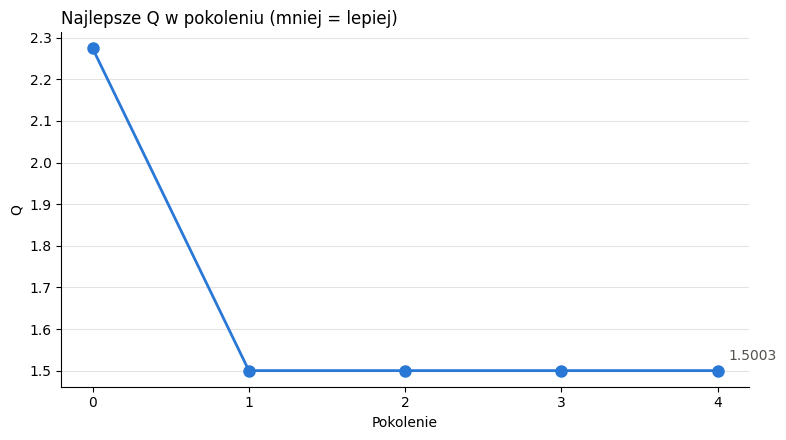

In [ ]:
# ==== Najlepsze Q w funkcji pokolenia ====
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(ga_history["generation"], ga_history["best_Q"],
        color="#2a78d6", linewidth=2, marker="o", markersize=8)

last = ga_history.iloc[-1]
ax.annotate(f"{last['best_Q']:.4f}", (last["generation"], last["best_Q"]),
            textcoords="offset points", xytext=(8, 8), color="#52514e")

ax.set_title("Najlepsze Q w pokoleniu (mniej = lepiej)", loc="left")
ax.set_xlabel("Pokolenie")
ax.set_ylabel("Q")
ax.set_xticks(ga_history["generation"])
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(GA_WORK_DIR / f"best_q_{run_id}.png", dpi=150)
plt.show()

In [ ]:
# ==== Testy ====
# encode -> decode zwraca te same wartości PID
print(decode(encode([1.59, 0.0062, 1.17])))  # [1.59 0.0062 1.17]

# Najlepszy znaleziony osobnik
best = population_ga.loc[population_ga["Q"].idxmin()]
print("Najlepszy PID:", best[pid_parameters].round(4).to_dict(), "Q =", round(best["Q"], 6))

[1.59   0.0062 1.17  ]
Najlepszy PID: {'P_gain': 3.5668, 'I_gain': 0.001, 'D_gain': 3.2849} Q = 1.50031
